In [8]:
# ============================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


# ============================================================
# 2. PARÁMETROS GENERALES
# ============================================================

TIEMPO_OPERACION = 480  # 8 horas expresadas en minutos
N_REPLICAS = 30
SEMILLA_BASE = 20261123

ACCIONES = ["Retiro", "Pago"]

TIPOS_USUARIO = [
    "Rápido",
    "Normal",
    "Lento",
    "Muy lento"
]

# Probabilidad de cada operación
PROB_ACCION = {
    "Retiro": 0.70,
    "Pago": 0.30
}

# Probabilidad de clasificación según la operación
PROB_TIPO = {
    "Retiro": [0.23, 0.40, 0.17, 0.20],
    "Pago": [0.10, 0.20, 0.30, 0.40]
}

# Media de los intervalos entre llegadas (minutos)
MEDIA_LLEGADA = {
    "Retiro": [1, 2, 3, 3],
    "Pago": [1, 2, 3, 4]
}

# Media de los tiempos de servicio (minutos)
MEDIA_SERVICIO = {
    "Retiro": [1, 2, 3, 4],
    "Pago": [3, 3, 5, 7]
}

# Categorías utilizadas para organizar los resultados
CATEGORIAS = [
    f"{accion} - {tipo}"
    for accion in ACCIONES
    for tipo in TIPOS_USUARIO
]


# ============================================================
# 3. CONFIGURACIONES DE CAJEROS
# ============================================================

ESCENARIOS = {

    "3 cajas mixtas": {
        "num_cajeros": 3,
        "Retiro": [0, 1, 2],
        "Pago": [0, 1, 2]
    },

    "1 retiro + 2 pagos": {
        "num_cajeros": 3,
        "Retiro": [0],
        "Pago": [1, 2]
    },

    "2 retiros + 1 pago": {
        "num_cajeros": 3,
        "Retiro": [0, 1],
        "Pago": [2]
    },

    "4 cajas mixtas": {
        "num_cajeros": 4,
        "Retiro": [0, 1, 2, 3],
        "Pago": [0, 1, 2, 3]
    }
}

# ============================================================
# 4. VALIDACIÓN DE LOS PARÁMETROS
# ============================================================

assert np.isclose(sum(PROB_ACCION.values()), 1)

for accion in ACCIONES:
    assert np.isclose(sum(PROB_TIPO[accion]), 1)

print("Parámetros y configuraciones definidos correctamente.")
print(f"Tiempo de operación: {TIEMPO_OPERACION} minutos")
print(f"Número de réplicas: {N_REPLICAS}")
print(f"Escenarios: {len(ESCENARIOS)}")


Parámetros y configuraciones definidos correctamente.
Tiempo de operación: 480 minutos
Número de réplicas: 30
Escenarios: 4


In [9]:
# ============================================================
# 1. GENERACIÓN DE USUARIOS PARA CADA RÉPLICA
# ============================================================

def generar_clientes_replica(semilla):

    # Generadores aleatorios independientes
    secuencia = np.random.SeedSequence(semilla)
    sem_llegadas, sem_servicios = secuencia.spawn(2)

    rng_llegadas = np.random.default_rng(sem_llegadas)
    rng_servicios = np.random.default_rng(sem_servicios)

    clientes = []

    tiempo = 0.0
    id_cliente = 1

    while True:

        # Seleccionar la operación del usuario
        accion = rng_llegadas.choice(
            ACCIONES,
            p=[PROB_ACCION[a] for a in ACCIONES]
        )

        # Seleccionar su clasificación
        indice_tipo = rng_llegadas.choice(
            len(TIPOS_USUARIO),
            p=PROB_TIPO[accion]
        )

        tipo = TIPOS_USUARIO[indice_tipo]

        # Generar el intervalo entre llegadas
        intervalo = rng_llegadas.exponential(
            MEDIA_LLEGADA[accion][indice_tipo]
        )

        tiempo += intervalo

        # No se generan nuevos usuarios después del cierre
        if tiempo > TIEMPO_OPERACION:
            break

        # Generar el tiempo de servicio
        servicio = rng_servicios.exponential(
            MEDIA_SERVICIO[accion][indice_tipo]
        )

        clientes.append({
            "id_cliente": id_cliente,
            "accion": accion,
            "tipo_usuario": tipo,
            "llegada": tiempo,
            "intervalo_llegada": intervalo,
            "servicio": servicio
        })

        id_cliente += 1

    return pd.DataFrame(clientes)


# ============================================================
# 2. SIMULACIÓN DE UN ESCENARIO DE CAJEROS
# ============================================================

def simular_escenario(clientes, configuracion, semilla_asignacion):

    rng = np.random.default_rng(semilla_asignacion)

    n_cajeros = configuracion["num_cajeros"]

    # Tiempo en el que cada cajero terminará su trabajo pendiente
    disponible_en = np.zeros(n_cajeros)

    registros = []

    for cliente in clientes.itertuples(index=False):

        # Obtener los cajeros habilitados para la operación
        elegibles = configuracion[cliente.accion]

        # Calcular el tiempo estimado de espera de cada cajero
        esperas = np.array([
            max(0, disponible_en[j] - cliente.llegada)
            for j in elegibles
        ])

        # Seleccionar el cajero que pueda atender más pronto
        espera_minima = esperas.min()

        # Resolver posibles empates aleatoriamente
        candidatos = [
            elegibles[i]
            for i, espera in enumerate(esperas)
            if np.isclose(espera, espera_minima, atol=1e-12)
        ]

        cajero = int(rng.choice(candidatos))

        # Calcular el inicio, espera y finalización del servicio
        inicio = max(
            cliente.llegada,
            disponible_en[cajero]
        )

        espera = inicio - cliente.llegada

        fin = inicio + cliente.servicio

        # Actualizar la disponibilidad del cajero
        disponible_en[cajero] = fin

        # Calcular cuánto tiempo estuvo ocupado durante la jornada
        ocupado_jornada = max(
            0,
            min(fin, TIEMPO_OPERACION) - max(inicio, 0)
        )

        registros.append({
            "id_cliente": cliente.id_cliente,
            "accion": cliente.accion,
            "tipo_usuario": cliente.tipo_usuario,
            "llegada": cliente.llegada,
            "cajero": cajero + 1,
            "inicio_servicio": inicio,
            "fin_servicio": fin,
            "espera": espera,
            "servicio": cliente.servicio,
            "tiempo_sistema": espera + cliente.servicio,
            "ocupado_jornada": ocupado_jornada,
            "completado_jornada": fin <= TIEMPO_OPERACION
        })

    return pd.DataFrame(registros)

# ============================================================
# 3. CÁLCULO DE PROMEDIOS E INTERVALOS DE CONFIANZA
# ============================================================

def resumir_con_ic(datos, grupos, variable):

    resumen = (
        datos.groupby(grupos)[variable]
        .agg(
            n="count",
            media="mean",
            desviacion="std"
        )
        .reset_index()
    )

    # Valor crítico de la distribución t de Student
    grados_libertad = (resumen["n"] - 1).clip(lower=1)

    t_critico = stats.t.ppf(
        0.975,
        grados_libertad
    )

    # Margen de error del intervalo de confianza
    margen = (
        t_critico
        * resumen["desviacion"].fillna(0)
        / np.sqrt(resumen["n"])
    )

    resumen["ic_95_inf"] = resumen["media"] - margen
    resumen["ic_95_sup"] = resumen["media"] + margen

    return resumen


print("Funciones del modelo definidas correctamente.")


Funciones del modelo definidas correctamente.


Ejecutando réplica 1/30...
Ejecutando réplica 2/30...
Ejecutando réplica 3/30...
Ejecutando réplica 4/30...
Ejecutando réplica 5/30...
Ejecutando réplica 6/30...
Ejecutando réplica 7/30...
Ejecutando réplica 8/30...
Ejecutando réplica 9/30...
Ejecutando réplica 10/30...
Ejecutando réplica 11/30...
Ejecutando réplica 12/30...
Ejecutando réplica 13/30...
Ejecutando réplica 14/30...
Ejecutando réplica 15/30...
Ejecutando réplica 16/30...
Ejecutando réplica 17/30...
Ejecutando réplica 18/30...
Ejecutando réplica 19/30...
Ejecutando réplica 20/30...
Ejecutando réplica 21/30...
Ejecutando réplica 22/30...
Ejecutando réplica 23/30...
Ejecutando réplica 24/30...
Ejecutando réplica 25/30...
Ejecutando réplica 26/30...
Ejecutando réplica 27/30...
Ejecutando réplica 28/30...
Ejecutando réplica 29/30...
Ejecutando réplica 30/30...

Simulación finalizada correctamente.
Registros generados: 23980

1. TIEMPO PROMEDIO DE ATENCIÓN POR CAJERO


,escenario,cajero,n,media,desviacion,ic_95_inf,ic_95_sup
6,3 cajas mixtas,1,30,3.325,0.543,3.122,3.527
7,3 cajas mixtas,2,30,3.232,0.472,3.056,3.408
8,3 cajas mixtas,3,30,3.081,0.427,2.921,3.240


Cajero más rápido: 3 (3.081 minutos)
Cajero más lento: 1 (3.325 minutos)

2. PROMEDIO DE USUARIOS POR CLASIFICACIÓN


,escenario,tipo_usuario,n,media,desviacion,ic_95_inf,ic_95_sup
8,3 cajas mixtas,Lento,30,41.400,3.558,40.071,42.729
9,3 cajas mixtas,Muy lento,30,51.433,7.677,48.567,54.300
10,3 cajas mixtas,Normal,30,68.033,10.108,64.259,71.808
11,3 cajas mixtas,Rápido,30,38.967,6.901,36.390,41.543



3. PROMEDIO DE USUARIOS POR OPERACIÓN Y CLASIFICACIÓN


,escenario,categoria,n,media,desviacion,ic_95_inf,ic_95_sup
16,3 cajas mixtas,Pago - Lento,30,18.233,3.360,16.979,19.488
17,3 cajas mixtas,Pago - Muy lento,30,23.900,5.013,22.028,25.772
18,3 cajas mixtas,Pago - Normal,30,11.500,3.401,10.230,12.770
19,3 cajas mixtas,Pago - Rápido,30,6.033,2.834,4.975,7.092
20,3 cajas mixtas,Retiro - Lento,30,23.167,4.035,21.660,24.673
21,3 cajas mixtas,Retiro - Muy lento,30,27.533,5.393,25.520,29.547
22,3 cajas mixtas,Retiro - Normal,30,56.533,9.598,52.949,60.117
23,3 cajas mixtas,Retiro - Rápido,30,32.933,5.717,30.799,35.068


... (12 outputs left out)


10. CARGA APROXIMADA DE LOS CAJEROS (RHO)


,escenario,cajero,n,media,desviacion,ic_95_inf,ic_95_sup
0,1 retiro + 2 pagos,1,30,0.683,0.083,0.652,0.714
1,1 retiro + 2 pagos,2,30,0.323,0.073,0.296,0.350
2,1 retiro + 2 pagos,3,30,0.316,0.072,0.289,0.344
3,2 retiros + 1 pago,1,30,0.334,0.049,0.316,0.353
4,2 retiros + 1 pago,2,30,0.348,0.047,0.331,0.366
5,2 retiros + 1 pago,3,30,0.639,0.128,0.592,0.687
6,3 cajas mixtas,1,30,0.445,0.057,0.424,0.467
7,3 cajas mixtas,2,30,0.445,0.051,0.426,0.464
8,3 cajas mixtas,3,30,0.432,0.060,0.410,0.454
9,4 cajas mixtas,1,30,0.335,0.048,0.317,0.353



11. SERVICIOS COMPLETADOS DURANTE LA JORNADA


categoria,escenario,replica,Retiro - Rápido,Retiro - Normal,Retiro - Lento,Retiro - Muy lento,Pago - Rápido,Pago - Normal,Pago - Lento,Pago - Muy lento
60,3 cajas mixtas,1,22,78,21,24,7,12,20,21
61,3 cajas mixtas,2,22,39,18,27,4,15,15,25
62,3 cajas mixtas,3,29,68,23,25,4,12,20,23
63,3 cajas mixtas,4,31,41,31,26,9,17,13,23
64,3 cajas mixtas,5,39,61,24,23,4,4,14,26
65,3 cajas mixtas,6,46,59,25,24,2,10,17,24
66,3 cajas mixtas,7,33,56,20,20,8,7,22,23
67,3 cajas mixtas,8,29,52,23,33,5,8,16,23
68,3 cajas mixtas,9,26,59,23,19,2,7,16,29
69,3 cajas mixtas,10,28,51,32,26,7,9,14,32


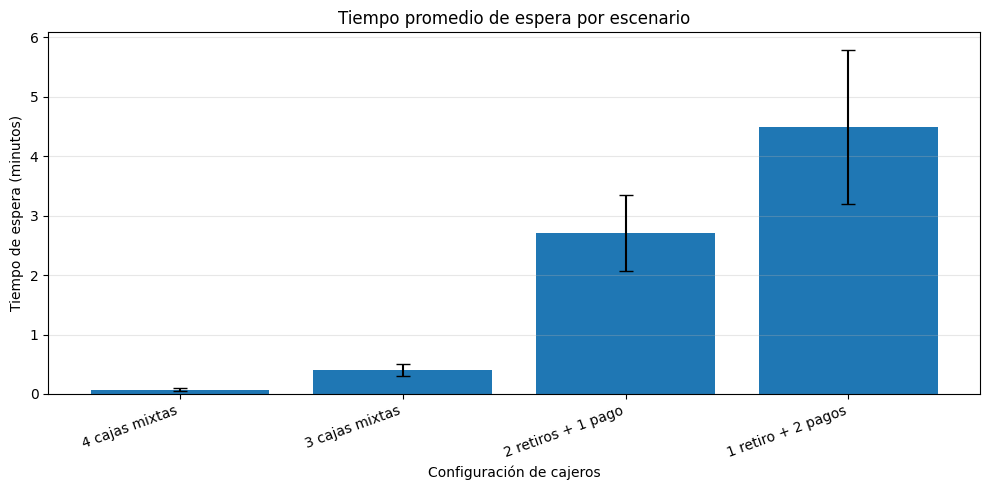

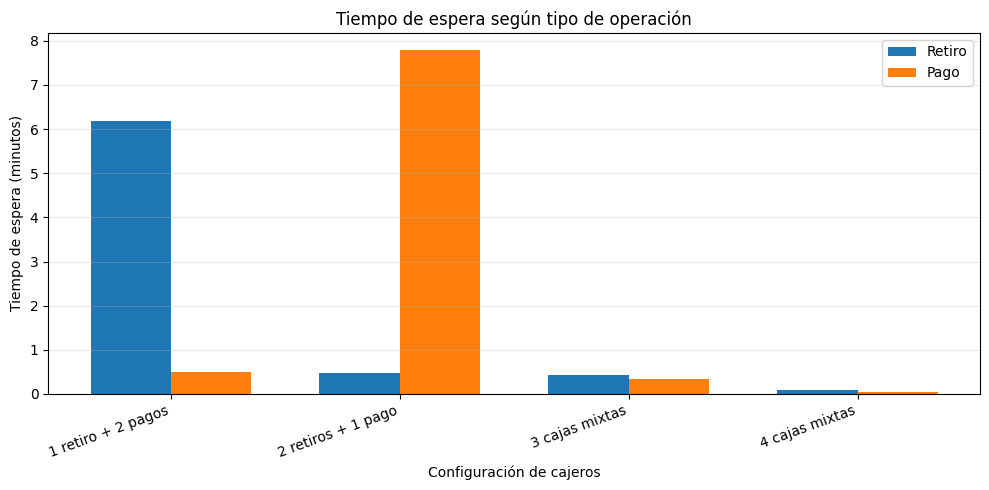

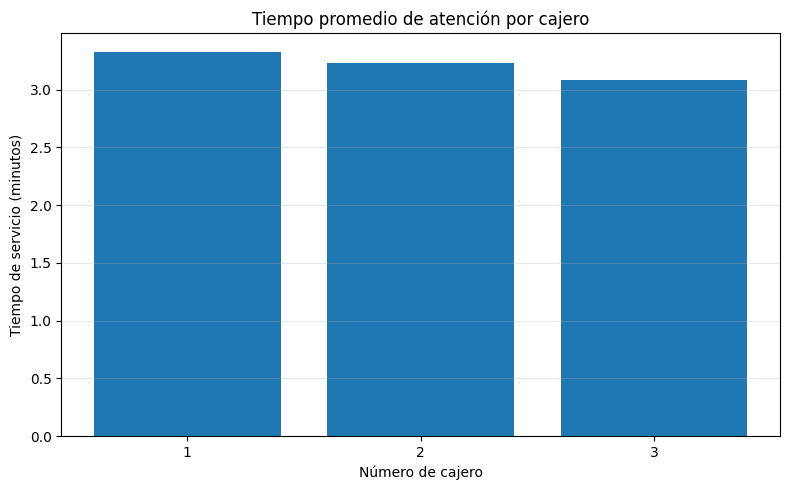


Archivo generado: resultados_simulacion_banco.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
# ============================================================
# 1. EJECUTAR LAS RÉPLICAS EN TODOS LOS ESCENARIOS
# ============================================================

registros = []

for replica in range(1, N_REPLICAS + 1):

    print(f"Ejecutando réplica {replica}/{N_REPLICAS}...")

    # Generar una única demanda para cada réplica
    clientes = generar_clientes_replica(
        SEMILLA_BASE + replica
    )

    # Utilizar la misma demanda en todos los escenarios
    for indice, (nombre, configuracion) in enumerate(
        ESCENARIOS.items()
    ):

        resultados = simular_escenario(
            clientes,
            configuracion,
            SEMILLA_BASE + replica + 1000 + indice
        )

        resultados["escenario"] = nombre
        resultados["replica"] = replica

        registros.append(resultados)


# Unificar los resultados
df_clientes = pd.concat(registros, ignore_index=True)

print("\nSimulación finalizada correctamente.")
print("Registros generados:", len(df_clientes))


# ============================================================
# 2. ESTADÍSTICAS DE TIEMPO POR CAJERO
# ============================================================

por_cajero_replica = (
    df_clientes.groupby(["escenario", "replica", "cajero"])
    .agg(
        usuarios=("id_cliente", "count"),
        tiempo_atencion=("servicio", "mean"),
        tiempo_espera=("espera", "mean"),
        tiempo_sistema=("tiempo_sistema", "mean"),
        minutos_ocupado=("ocupado_jornada", "sum")
    )
    .reset_index()
)

# Utilización observada durante los 480 minutos
por_cajero_replica["utilizacion"] = (
    por_cajero_replica["minutos_ocupado"] / TIEMPO_OPERACION
)

# Estimación de carga ofrecida (rho)
por_cajero_replica["rho_aproximado"] = (
    por_cajero_replica["usuarios"] / TIEMPO_OPERACION
    * por_cajero_replica["tiempo_atencion"]
)

# Estadísticas de atención por cajero
resumen_cajeros = resumir_con_ic(
    por_cajero_replica,
    ["escenario", "cajero"],
    "tiempo_atencion"
)

# Estadísticas de utilización
resumen_utilizacion = resumir_con_ic(
    por_cajero_replica,
    ["escenario", "cajero"],
    "utilizacion"
)

# Estadísticas de carga aproximada
resumen_rho = resumir_con_ic(
    por_cajero_replica,
    ["escenario", "cajero"],
    "rho_aproximado"
)

# Identificar los cajeros más rápido y más lento
base_cajeros = resumen_cajeros[
    resumen_cajeros["escenario"] == "3 cajas mixtas"
].copy()

mas_rapido = base_cajeros.loc[
    base_cajeros["media"].idxmin()
]

mas_lento = base_cajeros.loc[
    base_cajeros["media"].idxmax()
]


# ============================================================
# 3. ESTADÍSTICAS DE TIEMPOS DE ESPERA
# ============================================================

esperas_replica = []

for (escenario, replica), grupo in df_clientes.groupby(
    ["escenario", "replica"]
):

    # Criterios generales y por operación
    criterios = [
        ("Total", grupo),
        ("Retiro", grupo[grupo["accion"] == "Retiro"]),
        ("Pago", grupo[grupo["accion"] == "Pago"])
    ]

    # Criterios por operación y clasificación
    for accion in ACCIONES:

        for tipo in TIPOS_USUARIO:

            subgrupo = grupo[
                (grupo["accion"] == accion) &
                (grupo["tipo_usuario"] == tipo)
            ]

            criterios.append((
                f"{accion} - {tipo}",
                subgrupo
            ))

    # Registrar el tiempo promedio de cada criterio
    for criterio, subgrupo in criterios:

        if not subgrupo.empty:

            esperas_replica.append({
                "escenario": escenario,
                "replica": replica,
                "criterio": criterio,
                "espera_promedio": subgrupo["espera"].mean()
            })

df_esperas_replica = pd.DataFrame(esperas_replica)

resumen_esperas = resumir_con_ic(
    df_esperas_replica,
    ["escenario", "criterio"],
    "espera_promedio"
)

# Comparación general de escenarios
resumen_espera_total = resumen_esperas[
    resumen_esperas["criterio"] == "Total"
].sort_values("media")


# ============================================================
# 4. CANTIDAD DE USUARIOS POR TIPO Y RÉPLICA
# ============================================================

df_clientes["categoria"] = (
    df_clientes["accion"]
    + " - "
    + df_clientes["tipo_usuario"]
)

# Total de usuarios que llegan durante la jornada
conteos_llegadas = (
    df_clientes.groupby(["escenario", "replica", "categoria"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=CATEGORIAS, fill_value=0)
    .reset_index()
)

# Usuarios que terminan su atención antes del cierre
conteos_completados = (
    df_clientes[df_clientes["completado_jornada"]]
    .groupby(["escenario", "replica", "categoria"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=CATEGORIAS, fill_value=0)
    .reset_index()
)

# Promedio de usuarios rápidos, normales, lentos y muy lentos
conteos_tipo = conteos_llegadas[["escenario", "replica"]].copy()

for tipo in TIPOS_USUARIO:

    columnas = [
        f"{accion} - {tipo}"
        for accion in ACCIONES
    ]

    conteos_tipo[tipo] = conteos_llegadas[columnas].sum(axis=1)

conteos_tipo_largo = conteos_tipo.melt(
    id_vars=["escenario", "replica"],
    var_name="tipo_usuario",
    value_name="usuarios"
)

resumen_usuarios_tipo = resumir_con_ic(
    conteos_tipo_largo,
    ["escenario", "tipo_usuario"],
    "usuarios"
)

# Promedio por operación y clasificación
conteos_accion_tipo = conteos_llegadas.melt(
    id_vars=["escenario", "replica"],
    var_name="categoria",
    value_name="usuarios"
)

resumen_usuarios_accion_tipo = resumir_con_ic(
    conteos_accion_tipo,
    ["escenario", "categoria"],
    "usuarios"
)


# ============================================================
# 5. RÉPLICAS CON MENORES CANTIDADES DE USUARIOS
# ============================================================

# Menor cantidad de usuarios que llegaron por categoría
base_conteos = conteos_llegadas[
    conteos_llegadas["escenario"] == "3 cajas mixtas"
].copy()

minimos_llegadas = []

for categoria in CATEGORIAS:

    fila = base_conteos.loc[
        base_conteos[categoria].idxmin()
    ]

    minimos_llegadas.append({
        "categoria": categoria,
        "replica": int(fila["replica"]),
        "cantidad_minima": int(fila[categoria])
    })

minimos_llegadas = pd.DataFrame(minimos_llegadas)

# Escenario con menor promedio de servicios completados
promedio_completados = (
    conteos_completados.groupby("escenario")[CATEGORIAS]
    .mean()
)

minimos_completados = []

for categoria in CATEGORIAS:

    escenario = promedio_completados[categoria].idxmin()

    minimos_completados.append({
        "categoria": categoria,
        "escenario": escenario,
        "promedio_completado": promedio_completados.loc[
            escenario, categoria
        ]
    })

minimos_completados = pd.DataFrame(minimos_completados)


# ============================================================
# 6. MOSTRAR LAS TABLAS DE RESULTADOS
# ============================================================

print("\n1. TIEMPO PROMEDIO DE ATENCIÓN POR CAJERO")
display(base_cajeros.round(3))

print(
    f"Cajero más rápido: {int(mas_rapido['cajero'])} "
    f"({mas_rapido['media']:.3f} minutos)"
)

print(
    f"Cajero más lento: {int(mas_lento['cajero'])} "
    f"({mas_lento['media']:.3f} minutos)"
)


print("\n2. PROMEDIO DE USUARIOS POR CLASIFICACIÓN")
display(
    resumen_usuarios_tipo[
        resumen_usuarios_tipo["escenario"] == "3 cajas mixtas"
    ].round(3)
)


print("\n3. PROMEDIO DE USUARIOS POR OPERACIÓN Y CLASIFICACIÓN")
display(
    resumen_usuarios_accion_tipo[
        resumen_usuarios_accion_tipo["escenario"] == "3 cajas mixtas"
    ].round(3)
)


print("\n4. USUARIOS QUE LLEGARON EN CADA RÉPLICA")
display(
    conteos_llegadas[
        conteos_llegadas["escenario"] == "3 cajas mixtas"
    ]
)


print("\n5. RÉPLICAS CON MENOR CANTIDAD DE USUARIOS")
display(minimos_llegadas)


print("\n6. ESCENARIOS CON MENOR CANTIDAD DE SERVICIOS COMPLETADOS")
display(minimos_completados)


print("\n7. TIEMPOS PROMEDIO DE ESPERA POR CRITERIO")
display(resumen_esperas.round(3))


print("\n8. COMPARACIÓN GENERAL DE TIEMPOS DE ESPERA")
display(resumen_espera_total.round(3))


print("\n9. UTILIZACIÓN DE LOS CAJEROS")
display(resumen_utilizacion.round(3))


print("\n10. CARGA APROXIMADA DE LOS CAJEROS (RHO)")
display(resumen_rho.round(3))


print("\n11. SERVICIOS COMPLETADOS DURANTE LA JORNADA")
display(
    conteos_completados[
        conteos_completados["escenario"] == "3 cajas mixtas"
    ]
)


# ============================================================
# 7. GRÁFICAS COMPARATIVAS
# ============================================================

# Gráfica 1: tiempo de espera general por escenario

plt.figure(figsize=(10, 5))

plt.bar(
    resumen_espera_total["escenario"],
    resumen_espera_total["media"],
    yerr=[
        resumen_espera_total["media"] - resumen_espera_total["ic_95_inf"],
        resumen_espera_total["ic_95_sup"] - resumen_espera_total["media"]
    ],
    capsize=5
)

plt.title("Tiempo promedio de espera por escenario")
plt.xlabel("Configuración de cajeros")
plt.ylabel("Tiempo de espera (minutos)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfica 2: tiempo de espera por operación

datos_acciones = resumen_esperas[
    resumen_esperas["criterio"].isin(["Retiro", "Pago"])
]

tabla_acciones = datos_acciones.pivot(
    index="escenario",
    columns="criterio",
    values="media"
)

x = np.arange(len(tabla_acciones))
ancho = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - ancho / 2,
    tabla_acciones["Retiro"],
    ancho,
    label="Retiro"
)

plt.bar(
    x + ancho / 2,
    tabla_acciones["Pago"],
    ancho,
    label="Pago"
)

plt.title("Tiempo de espera según tipo de operación")
plt.xlabel("Configuración de cajeros")
plt.ylabel("Tiempo de espera (minutos)")
plt.xticks(x, tabla_acciones.index, rotation=20, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Gráfica 3: tiempo de atención por cajero
# En el escenario inicial de tres cajas mixtas

plt.figure(figsize=(8, 5))

plt.bar(
    base_cajeros["cajero"].astype(str),
    base_cajeros["media"]
)

plt.title("Tiempo promedio de atención por cajero")
plt.xlabel("Número de cajero")
plt.ylabel("Tiempo de servicio (minutos)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 8. EXPORTACIÓN DE RESULTADOS A EXCEL
# ============================================================

nombre_archivo = "resultados_simulacion_banco.xlsx"

with pd.ExcelWriter(nombre_archivo) as writer:

    df_clientes.to_excel(
        writer, sheet_name="Datos_simulacion", index=False
    )

    resumen_cajeros.to_excel(
        writer, sheet_name="Tiempo_cajeros", index=False
    )

    resumen_esperas.to_excel(
        writer, sheet_name="Tiempos_espera", index=False
    )

    conteos_llegadas.to_excel(
        writer, sheet_name="Usuarios_llegadas", index=False
    )

    conteos_completados.to_excel(
        writer, sheet_name="Servicios_completados", index=False
    )

    resumen_usuarios_tipo.to_excel(
        writer, sheet_name="Promedio_usuarios", index=False
    )

    resumen_utilizacion.to_excel(
        writer, sheet_name="Utilizacion", index=False
    )

    resumen_rho.to_excel(
        writer, sheet_name="Carga_cajeros", index=False
    )

    minimos_llegadas.to_excel(
        writer, sheet_name="Minimos_llegadas", index=False
    )

    minimos_completados.to_excel(
        writer, sheet_name="Minimos_completados", index=False
    )

print(f"\nArchivo generado: {nombre_archivo}")

# Descargar el archivo directamente desde Google Colab
from google.colab import files
files.download(nombre_archivo)
